# PathPack v1.0 — Evidence Graph Optimization

Диагностические 20 задач. Числа читаются из `output/v10_diag` и `output/v10_baselines`. v0.4 не заменён. Конфиг после прогона не менялся. Holdout не оценивался. Embedding-канал в статусe `not_run`.


In [1]:
from pathlib import Path
import json, gzip
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'output').exists():
    ROOT = ROOT.parent
diag = ROOT / 'output/v10_diag'
base = ROOT / 'output/v10_baselines'
summary = pd.read_csv(diag / 'summary.csv')
baselines = pd.read_csv(base / 'summary.csv')
cols = ['method','file_recall','function_recall','complete_function_recall','changed_line_recall','token_utilization','latency_sec']
view = summary.loc[summary.budget==2048, cols].copy()
print(view.round(4).to_string(index=False))
print('\nbaselines')
print(baselines.loc[baselines.budget==2048, cols].round(4).to_string(index=False))


                    method  file_recall  function_recall  complete_function_recall  changed_line_recall  token_utilization  latency_sec
              pathpack-v10        0.475           0.1706                    0.0595               0.0765             0.3483       0.3287
     pathpack-v10/coverage        0.425           0.0556                    0.0556               0.0714             0.1201       0.3291
       pathpack-v10/nested        0.500           0.2024                    0.0913               0.1820             0.3988       0.3440
  pathpack-v10/no-semantic        0.475           0.1706                    0.0595               0.0765             0.3483       0.3366
pathpack-v10/no-structural        0.425           0.0556                    0.0556               0.0714             0.1201       0.3309
        pathpack-v10/paths        0.375           0.1944                    0.0833               0.1667             0.5013       0.3282
               pathpack-v4        0.725         

## Сравнение с v0.4 и абляции при 2048

Столбцы — средние по оцениваемым задачам. File по 20, Function и Complete по 18, Changed Line по 14.


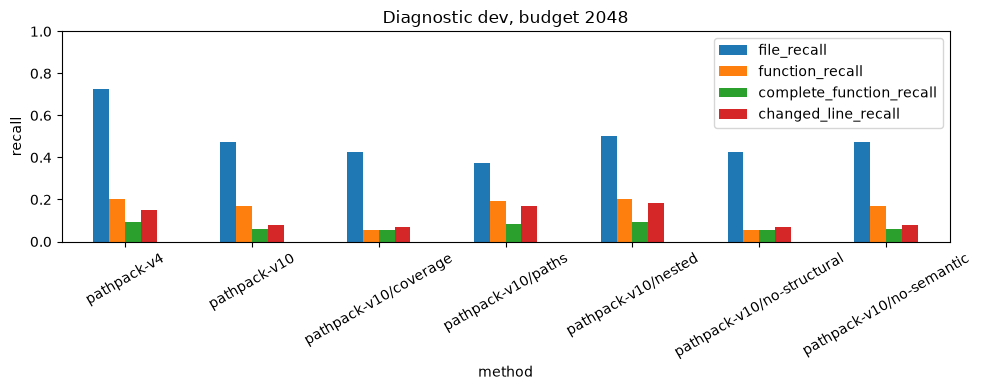

In [3]:
metrics = ['file_recall','function_recall','complete_function_recall','changed_line_recall']
order = ['pathpack-v4','pathpack-v10','pathpack-v10/coverage','pathpack-v10/paths','pathpack-v10/nested','pathpack-v10/no-structural','pathpack-v10/no-semantic']
plot = view.set_index('method').loc[order, metrics]
ax = plot.plot.bar(figsize=(10, 4), rot=30)
ax.set_ylim(0, 1)
ax.set_ylabel('recall')
ax.set_title('Diagnostic dev, budget 2048')
plt.tight_layout()
plt.show()


## Bootstrap: joint и группы минус v0.4

Разница — кандидат минус v0.4. Интервал 95%, 2000 перестановок, seed 42. Положительная победа означает, что кандидат выше на этой задаче.


                 candidate                   metric  n  difference                   ci95  wins  ties  losses
              pathpack-v10              file_recall 20   -0.250000        [-0.525, 0.025]     3     9       8
              pathpack-v10          function_recall 18   -0.031746  [-0.194444, 0.154762]     1    14       3
              pathpack-v10 complete_function_recall 18   -0.031746       [-0.087302, 0.0]     0    16       2
              pathpack-v10      changed_line_recall 14   -0.071429       [-0.214286, 0.0]     0    13       1
     pathpack-v10/coverage              file_recall 20   -0.300000         [-0.55, -0.05]     2    10       8
     pathpack-v10/coverage          function_recall 18   -0.146825 [-0.313492, -0.007937]     0    14       4
     pathpack-v10/coverage complete_function_recall 18   -0.035714       [-0.095238, 0.0]     0    16       2
     pathpack-v10/coverage      changed_line_recall 14   -0.076531        [-0.22449, 0.0]     0    12       2
        pa

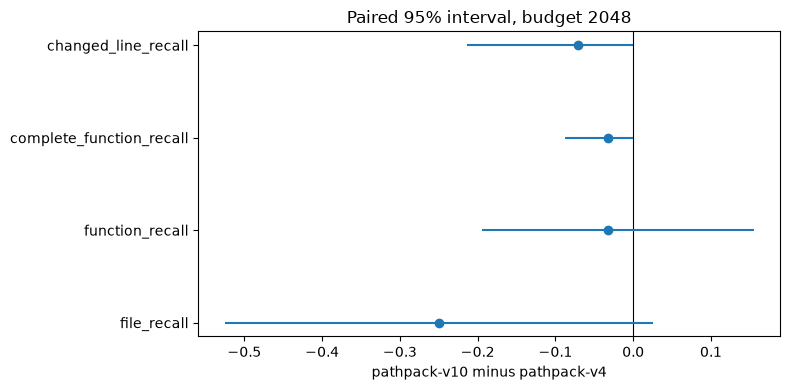

In [5]:
comps = pd.read_json(diag / 'comparisons.json')
focus = comps[(comps.budget==2048) & (comps.baseline=='pathpack-v4') & (comps.candidate.str.startswith('pathpack-v10'))]
focus = focus[focus.metric.isin(metrics)][['candidate','metric','n','difference','ci95','wins','ties','losses']]
print(focus.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4))
joint = focus[focus.candidate=='pathpack-v10'].set_index('metric').loc[metrics]
ax.axvline(0, color='black', lw=0.8)
ax.errorbar(joint.difference, range(len(joint)),
            xerr=[joint.difference-joint.ci95.map(lambda x: x[0]), joint.ci95.map(lambda x: x[1])-joint.difference],
            fmt='o')
ax.set_yticks(range(len(joint)))
ax.set_yticklabels(joint.index)
ax.set_xlabel('pathpack-v10 minus pathpack-v4')
ax.set_title('Paired 95% interval, budget 2048')
plt.tight_layout()
plt.show()


## BM25, graph expansion и v0.9

Те же 20 задач и тот же счётчик, второй каталог прогона. Embedding-only и смесь lexical+embedding отсутствуют: модель не установлена.


In [7]:
from codegraph_rag.audit import paired_bootstrap
def scores(path):
    rows = [json.loads(line) for line in path.read_text().splitlines() if line.strip()]
    return pd.DataFrame(rows)
ego = scores(diag/'scores.jsonl')
other = scores(base/'scores.jsonl')
ego2048 = ego[ego.budget==2048]
other2048 = other[other.budget==2048]
rows = []
for method in ['bm25','graph-expand','pathpack-v9','pathpack-v4']:
    right = other2048[other2048.method==method]
    left = ego2048[ego2048.method=='pathpack-v10']
    for metric in metrics:
        a = dict(zip(left.instance_id, left[metric]))
        b = dict(zip(right.instance_id, right[metric]))
        a = {k:v for k,v in a.items() if pd.notna(v)}
        b = {k:v for k,v in b.items() if pd.notna(v)}
        stat = paired_bootstrap(a, b, iterations=2000, seed=42)
        rows.append({'baseline': method, 'metric': metric, **stat})
print(pd.DataFrame(rows).to_string(index=False))


    baseline                   metric  n  difference                  ci95  wins  ties  losses
        bm25              file_recall 20    0.125000       [-0.075, 0.325]     4    15       1
        bm25          function_recall 18    0.059524 [-0.111111, 0.234127]     3    14       1
        bm25 complete_function_recall 18   -0.051587 [-0.166667, 0.011905]     1    16       1
        bm25      changed_line_recall 14   -0.066327 [-0.214286, 0.015306]     1    12       1
graph-expand              file_recall 20    0.150000          [-0.15, 0.4]     6    11       3
graph-expand          function_recall 18    0.059524 [-0.111111, 0.234127]     3    14       1
graph-expand complete_function_recall 18   -0.051587 [-0.166667, 0.011905]     1    16       1
graph-expand      changed_line_recall 14   -0.066327 [-0.214286, 0.015306]     1    12       1
 pathpack-v9              file_recall 20   -0.475000        [-0.7, -0.275]     0    10      10
 pathpack-v9          function_recall 18   -0.0317

## Пул до упаковки и расход бюджета

File Pool Recall — доля золотых файлов, которые вообще попали в объединение каналов. Упакованный recall — доля, дошедшая до контекста.


                            file_pool_recall  file_packed_recall  function_pool_recall  function_packed_recall
method                                                                                                        
pathpack-v10                            0.85               0.475                 0.619                  0.1905
pathpack-v10/coverage                   0.85               0.425                 0.619                  0.1230
pathpack-v10/nested                     0.85               0.500                 0.619                  0.2460
pathpack-v10/no-semantic                0.85               0.475                 0.619                  0.1905
pathpack-v10/no-structural              0.85               0.425                 0.619                  0.1230
pathpack-v10/paths                      0.85               0.375                 0.619                  0.2341


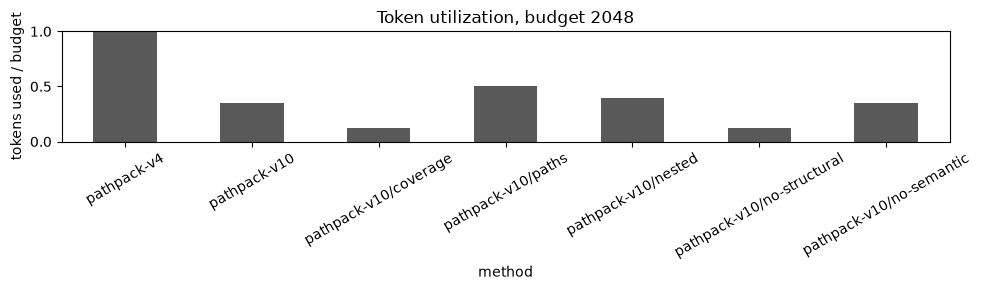

In [9]:
pool = pd.read_csv(diag/'pool_recall.csv')
pool = pool[pool.budget==2048]
means = pool.groupby('method')[['file_pool_recall','file_packed_recall','function_pool_recall','function_packed_recall']].mean()
print(means.round(4).to_string())
use = summary[summary.budget==2048].set_index('method').loc[order, 'token_utilization']
ax = use.plot.bar(figsize=(10, 3), rot=30, color='0.35')
ax.set_ylim(0, 1)
ax.set_ylabel('tokens used / budget')
ax.set_title('Token utilization, budget 2048')
plt.tight_layout()
plt.show()


## Одна задача: свидетельства, каналы и выбранные функции

`django__django-12276`. Золотые файлы читаются из файла оценки, не из отбора.


In [11]:
iid = 'django__django-12276'
with gzip.open(diag/'diagnostics'/f'{iid}_v10joint_2048.json.gz','rt') as handle:
    record = json.load(handle)
print('channels', json.dumps(record['channels'], ensure_ascii=False))
print('evidence')
for item in record['evidence']:
    print(' ', item['type'], item['confidence'], item['query_span'][:90])
selected = [c for c in record['candidates'] if c.get('selected')]
print('selected', len(selected), 'pool', len(record['candidates']))
for c in selected:
    print(' ', c['path'], c['qualname'], c['sources'], c['evidence_ids'])
labels = pd.read_json(diag/'scoring_labels.jsonl', lines=True)
gold_files = labels.loc[labels.instance_id==iid, 'gold_python_files'].iloc[0]
packed = sorted({c['path'] for c in selected})
print('gold files', gold_files)
print('packed files', packed)
print('gold files absent from pack', sorted(set(gold_files)-set(packed)))


channels {"bm25": {"kept": 64, "dropped": 12907, "reason": "bm25_limit"}, "symbol": {"kept": 14, "dropped": 0, "reason": ""}, "path": {"kept": 32, "dropped": 86, "reason": "path_limit"}, "embedding": {"kept": 0, "dropped": 0, "reason": "sentence-transformers is not installed. No weights were downloaded and no lexical method was substituted under this name.", "status": "not_run"}, "graph": {"kept": 1, "dropped": 0, "reason": "", "unresolved_calls_omitted": true}, "test": {"kept": 0, "dropped": 0, "reason": "no_test_evidence"}}
evidence
  path 0.9 github.com/django/django/blob/e703b93a656b78b9b444bb3a9980e305ed002a70/django/forms/widget
  symbol 0.6 FileInput
  symbol 0.6 ClearableFileInput
  symbol 0.6 use_required_attribute
selected 2 pool 88
  django/forms/widgets.py ClearableFileInput.use_required_attribute ['bm25', 'symbol', 'path'] ['path:0:github.com/django/django/blob/e703b93a656b78b9b4', 'symbol:2:clearablefileinput', 'symbol:3:use_required_attribute']
  django/forms/widgets.py 

In [12]:
import networkx as nx
graph = nx.DiGraph()
for item in record['evidence']:
    graph.add_node(item['evidence_id'], kind='evidence')
for c in record['candidates']:
    if not c.get('evidence_ids'):
        continue
    node = c['qualname']
    graph.add_node(node, kind='code')
    for evidence_id in c['evidence_ids']:
        graph.add_edge(evidence_id, node)
print('evidence-linked code nodes', sum(1 for _, data in graph.nodes(data=True) if data.get('kind')=='code'))
print('edges', graph.number_of_edges())
drawn = [c['qualname'] for c in selected]
print('selected component', drawn)


evidence-linked code nodes 33
edges 48
selected component ['ClearableFileInput.use_required_attribute', 'FileInput.format_value']
